# Sensitivity analysis (video #4)

Python version of *Sensitivity Analysis of Decision Tree (#4)*. In Radiant: **Load example > Sensitivity analysis**, then the _Sensitivity_ tab.

## Example 2

> You are an actor and would like to sign a contract with either a movie company or a TV network. If you sign with a movie company, you need to pay $5,000 for the legal fees. There will be a 30% chance of having small box office and earning $200,000, a 60% chance of having medium box office with payoff equal to $1,000,000, and a 10% chance of having large box office and getting $3,000,000. If you decide to sign the contract with TV networks instead, your payoff will be $900,000. What is EMV of signing the contract with movie company? What is your optimal strategy?

In [1]:
import pyrsm as rsm
from IPython.display import Markdown


def show(tree, final=True):
    """Draw a decision tree (Mermaid; rendered by JupyterLab, VS Code, Quarto)."""
    return Markdown(f"```mermaid\n{tree.to_mermaid(final=final)}\n```")

## Method 1: edit the value

### Legal fees of $5,000

In [2]:
fees_5000 = """name: Sign contract
type: decision
Sign with Movie Company:
    cost: 5000
    type: chance
    Small Box Office:
        p: 0.3
        payoff: 200000
    Medium Box Office:
        p: 0.6
        payoff: 1000000
    Large Box Office:
        p: 0.1
        payoff: 3000000
Sign with TV Network:
    payoff: 900000
"""

In [3]:
tree = rsm.decide.dtree(fees_5000)
tree.summary(input=False, output=True)


Initial decision tree:
                             Probability       Payoff     Cost     Type
 Sign contract                                                         
  ¦--Sign with Movie Company                          5,000.00 decision
  ¦   ¦--Small Box Office        30.00 %   200,000.00            chance
  ¦   ¦--Medium Box Office       60.00 % 1,000,000.00            chance
  ¦   °--Large Box Office        10.00 % 3,000,000.00            chance
  °--Sign with TV Network                  900,000.00          decision

Final decision tree:
                             Probability       Payoff     Cost     Type
 Sign contract                             955,000.00                  
  ¦--Sign with Movie Company               955,000.00 5,000.00 decision
  ¦   ¦--Small Box Office        30.00 %   200,000.00            chance
  ¦   ¦--Medium Box Office       60.00 % 1,000,000.00            chance
  ¦   °--Large Box Office        10.00 % 3,000,000.00            chance
  °--Sign with TV 

Signing with the movie company is worth $955,000, the TV network $900,000: sign with the movie company.

### Legal fees of $8,000

In [4]:
fees_8000 = """name: Sign contract
type: decision
Sign with Movie Company:
    cost: 8000
    type: chance
    Small Box Office:
        p: 0.3
        payoff: 200000
    Medium Box Office:
        p: 0.6
        payoff: 1000000
    Large Box Office:
        p: 0.1
        payoff: 3000000
Sign with TV Network:
    payoff: 900000
"""

In [5]:
tree = rsm.decide.dtree(fees_8000)
tree.summary(input=False, output=True)


Initial decision tree:
                             Probability       Payoff     Cost     Type
 Sign contract                                                         
  ¦--Sign with Movie Company                          8,000.00 decision
  ¦   ¦--Small Box Office        30.00 %   200,000.00            chance
  ¦   ¦--Medium Box Office       60.00 % 1,000,000.00            chance
  ¦   °--Large Box Office        10.00 % 3,000,000.00            chance
  °--Sign with TV Network                  900,000.00          decision

Final decision tree:
                             Probability       Payoff     Cost     Type
 Sign contract                             952,000.00                  
  ¦--Sign with Movie Company               952,000.00 8,000.00 decision
  ¦   ¦--Small Box Office        30.00 %   200,000.00            chance
  ¦   ¦--Medium Box Office       60.00 % 1,000,000.00            chance
  ¦   °--Large Box Office        10.00 % 3,000,000.00            chance
  °--Sign with TV 

With $8,000 in legal fees the movie company is worth $952,000: still the best option.

## Method 2: use a variable

Put the legal fees in a `variables:` section, then let them vary from 0 to $100,000 in steps of $10,000.

In [6]:
fees_variable = """name: Sign contract
variables:
    legal fees: 5000
type: decision
Sign with Movie Company:
    cost: legal fees
    type: chance
    Small Box Office:
        p: 0.3
        payoff: 200000
    Medium Box Office:
        p: 0.6
        payoff: 1000000
    Large Box Office:
        p: 0.1
        payoff: 3000000
Sign with TV Network:
    payoff: 900000
"""

In [7]:
tree = rsm.decide.dtree(fees_variable)
sens = tree.sensitivity({"legal fees": {"min": 0, "max": 100000, "step": 10000}})
sens.to_frame()

,legal fees,payoff,chosen,error_codes
0,0.0,960000.0,Sign with Movie Company,
1,10000.0,950000.0,Sign with Movie Company,
2,20000.0,940000.0,Sign with Movie Company,
3,30000.0,930000.0,Sign with Movie Company,
4,40000.0,920000.0,Sign with Movie Company,
5,50000.0,910000.0,Sign with Movie Company,
6,60000.0,900000.0,Sign with Movie Company; Sign with TV Network,
7,70000.0,900000.0,Sign with TV Network,
8,80000.0,900000.0,Sign with TV Network,
9,90000.0,900000.0,Sign with TV Network,


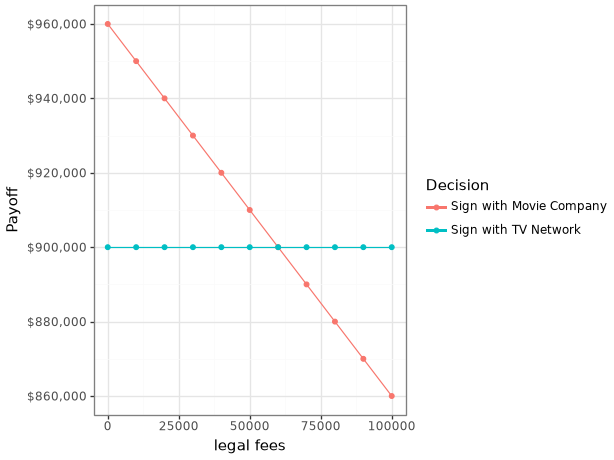

In [8]:
sens.plot(decisions=["Sign with Movie Company", "Sign with TV Network"])

Below $60,000 in legal fees sign with the movie company; above $60,000 sign with the TV network. At $60,000 the actor is indifferent between the two.

In [9]:
sens.threshold_flips()

[{'variable': 'legal fees', 'from_value': 50000.0, 'to_value': 60000.0, 'from_chosen': ['Sign with Movie Company'], 'to_chosen': ['Sign with Movie Company', 'Sign with TV Network']}, {'variable': 'legal fees', 'from_value': 60000.0, 'to_value': 70000.0, 'from_chosen': ['Sign with Movie Company', 'Sign with TV Network'], 'to_chosen': ['Sign with TV Network']}]